# Calibration of the inherent strain: block

Finds the inherent strain that makes the FE residual stress (sigma_xx on x = 7.5 mm of the 15 x 10 x 12 mm block, cut off Zhang's base plate) match the measured map of Zhang et al. 2025 (digitised Fig. 10b).

- **Material:** Zhang's tables (room-temperature row), see README.
- **Method:** inherent strain with alp_x = alp_y = a (Liang et al. 2019), alp_z fixed, layer by layer.
- **Search:** `fit` / `ladder` in `calibration.py`: a quadratic model of the whole stress field is fitted to the runs and minimised, then the proposal is simulated, and so on (README section 4).

## 1. Imports

In [1]:
import sys
from pathlib import Path
from ansys.mapdl.core import launch_mapdl

sys.path.insert(0, str(Path("mapdl").resolve()))     # folder with the .py files

from configuration import Config
from block import Block
from baseplate import BasePlate
from calibration import Calibration, NAMES

## 2. Settings

`LAYER` is the layer thickness *and* the element height, so it is the lumping: Zhang's 0.5 mm is about 17 physical layers, 1 mm about 33. A vector is only valid for the layer thickness it was calibrated at; section 4 helps to choose it. `SKIN` and `TOP` only define where the factors `fs` and `ft` act (the factors themselves are searched).

In [2]:
ELEM, LAYER = 1.0, 0.5      # mm: in-plane element size, layer thickness (= element height)
AZ, EDGE    = 0.005, 1.0    # fixed alp_z; points closer than EDGE mm to the map border are left out of the loss
SKIN, TOP   = 1.0, 1.0      # mm: skin width (multiple of the element size), top depth (rounded to whole layers)
PLATE_DZ    = 2.5           # mm: element size through the 15 mm base plate (None = like the part, slow)
CSV = Calibration.find("data", "Fig10b_block.csv")

def make(layer=None, elem=ELEM):
    layer = layer or LAYER
    cfg = Config(elem_size=elem, layer_h=layer, elem_z=layer, skin_width=SKIN, top_zone=max(1, round(TOP / layer)) * layer)
    return Block(mapdl, cfg, plate=BasePlate(25, 25, 15, dz=PLATE_DZ, support="corners"))

## 3. Start MAPDL and run the first guess

One simulation with a = -0.0044 and no zone effect. The maps should be smooth and look like the measured one.

11608 target points, 8000 in the loss | Zhang GB model vs measured: loss 42.9, all 60.4, within 100 MPa 89 %
12 saved runs in calibration_runs\Block_dc0d027cb2  (layer 0.5 mm, elements 1 mm)
a, ft, fs, r = (-0.003637, 1.0, 1.0, 1.0) | loss 47.2, all 60.3, bias +0.7, within 100 MPa 89.6 % | model vs Zhang GB: 28.3


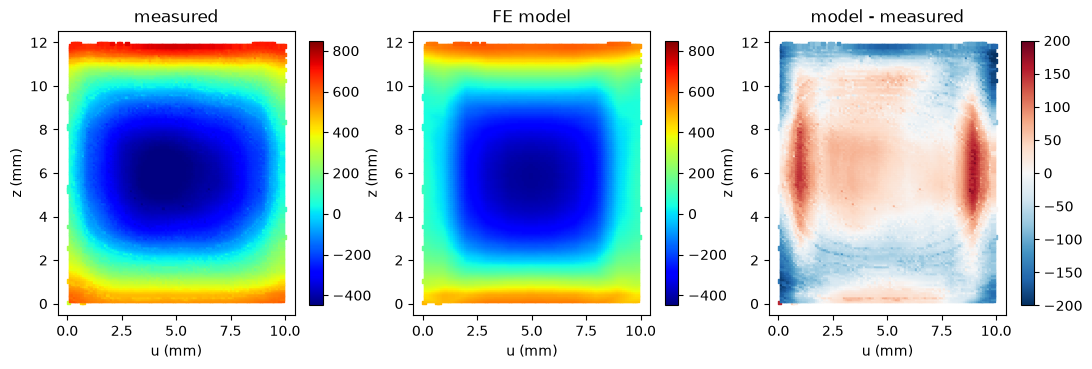

In [3]:
mapdl = launch_mapdl(nproc=4, loglevel="ERROR")
cal = Calibration(make(), CSV, EDGE, AZ)
cal.run()
cal.report();

## 4. Which layer thickness? (optional, change `LAYER` above to the best one)

Best `a` for each layer thickness, nothing else free (about 8 to 13 runs each). Compare the `loss` values: the saved runs are kept per thickness, so running it again is free.

In [4]:
loss = {h: Calibration(make(h), CSV, EDGE, AZ).fit(["a"])["loss"] for h in (0.5, 0.75, 1.0)}
LAYER = min(loss, key=loss.get)
cal = Calibration(make(), CSV, EDGE, AZ)
print(f"\nloss per layer: {loss}  ->  LAYER = {LAYER} mm")

11608 target points, 8000 in the loss | Zhang GB model vs measured: loss 42.9, all 60.4, within 100 MPa 89 %
1 saved runs in calibration_runs\Block_dc0d027cb2  (layer 0.5 mm, elements 1 mm)
run 002  layer=0.5  a=-0.00720 ft=1.000 fs=1.000 r=1.000  loss  55.0  all  67.2  bias  +0.6  within 100 MPa 86.4 %  (191s)
run 003  layer=0.5  a=-0.00810 ft=1.000 fs=1.000 r=1.000  loss  54.3  all  67.2  bias  +0.8  within 100 MPa 86.3 %  (180s)
run 004  layer=0.5  a=-0.01063 ft=1.000 fs=1.000 r=1.000  loss  53.3  all  68.1  bias  +1.3  within 100 MPa 85.8 %  (176s)
run 005  layer=0.5  a=-0.00917 ft=1.000 fs=1.000 r=1.000  loss  53.6  all  67.5  bias  +1.0  within 100 MPa 86.0 %  (179s)
run 006  layer=0.5  a=-0.00602 ft=1.000 fs=1.000 r=1.000  loss  56.9  all  67.7  bias  +0.3  within 100 MPa 86.5 %  (162s)
run 007  layer=0.5  a=-0.00330 ft=1.000 fs=1.000 r=1.000  loss  57.5  all  72.8  bias  +1.4  within 100 MPa 86.0 %  (132s)
run 008  layer=0.5  a=-0.00430 ft=1.000 fs=1.000 r=1.000  loss  55.7  al

In [4]:
# optional (only if kernel interrupted afer cell 4 is done)
LAYER = 0.75 # manually selecting the value based on cell 4's output
cal = Calibration(make(), CSV, EDGE, AZ)

11608 target points, 8000 in the loss | Zhang GB model vs measured: loss 42.9, all 60.4, within 100 MPa 89 %
13 saved runs in calibration_runs\Block_c84ae49e36  (layer 0.75 mm, elements 1 mm)


## 5. Calibrate: the ladder

L0 `a`, L1 adds the top factor `ft` and the skin factor `fs`, L2 adds `r` = ay / ax. Each level starts from the runs of the one before, so the table shows what each addition gained. Run it again to carry on; stop it any time (every run is saved).

In [5]:
# raise KeyboardInterrupt("Stopped run-all queue.")
cal.ladder();

fit round 1: surrogate (fit error 5.4 MPa, 12 runs) proposes a=-0.00374, predicted loss 37.4
run 014  layer=0.75  a=-0.00374 ft=1.000 fs=1.000 r=1.000  loss  47.2  all  64.4  bias  +1.7  within 100 MPa 89.1 %  (77s)
fit round 2: surrogate (fit error 7.0 MPa, 12 runs) proposes a=-0.00394, predicted loss 38.4
run 015  layer=0.75  a=-0.00394 ft=1.000 fs=1.000 r=1.000  loss  40.6  all  56.1  bias  +1.2  within 100 MPa 90.8 %  (77s)
fit: no gain over 0.1 MPa in 2 rounds, stopped
run 016  layer=0.75  a=-0.00327 ft=1.319 fs=1.688 r=1.000  loss  58.8  all  67.6  bias  +0.2  within 100 MPa 86.4 %  (86s)
run 017  layer=0.75  a=-0.01003 ft=1.756 fs=1.126 r=1.000  loss  51.1  all  62.4  bias  +1.5  within 100 MPa 88.3 %  (97s)
run 018  layer=0.75  a=-0.00521 ft=1.481 fs=0.637 r=1.000  loss  45.9  all  60.6  bias  +1.3  within 100 MPa 90.1 %  (86s)
run 019  layer=0.75  a=-0.00787 ft=0.555 fs=1.099 r=1.000  loss  53.9  all  62.5  bias  +0.3  within 100 MPa 89.0 %  (91s)
run 020  layer=0.75  a=-0.009

## 6. Result and fine-mesh check

Maps of the best run, then that vector once on 0.5 mm elements (Zhang's mesh).

a, ft, fs, r = (-0.004182, 1.0, 1.0, 1.0) | loss 38.1, all 50.8, bias +0.7, within 100 MPa 92.5 % | model vs Zhang GB: 27.0


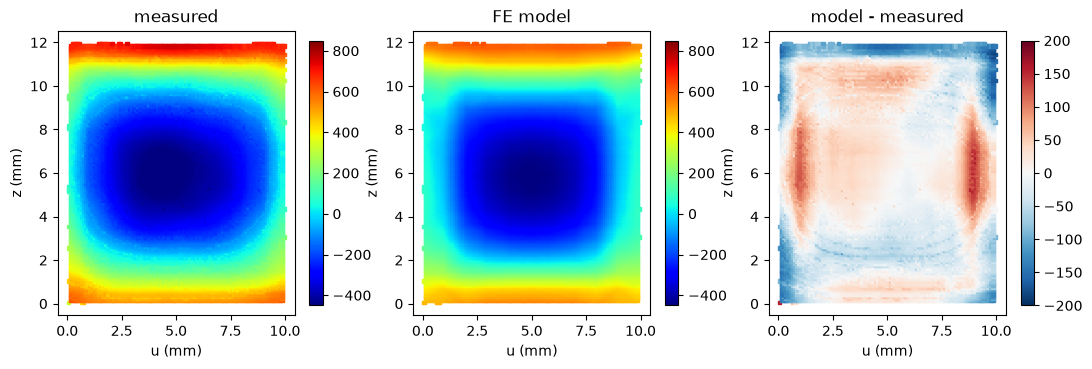

11608 target points, 8000 in the loss | Zhang GB model vs measured: loss 42.9, all 60.4, within 100 MPa 89 %
0 saved runs in calibration_runs\Block_9463f5ed39  (layer 0.75 mm, elements 0.5 mm)
run 001  layer=0.75  a=-0.00418 ft=1.000 fs=1.000 r=1.000  loss  34.8  all  50.6  bias  -0.4  within 100 MPa 92.7 %  (493s)
a, ft, fs, r = (-0.004182, 1.0, 1.0, 1.0) | loss 34.8, all 50.6, bias -0.4, within 100 MPa 92.7 % | model vs Zhang GB: 32.3


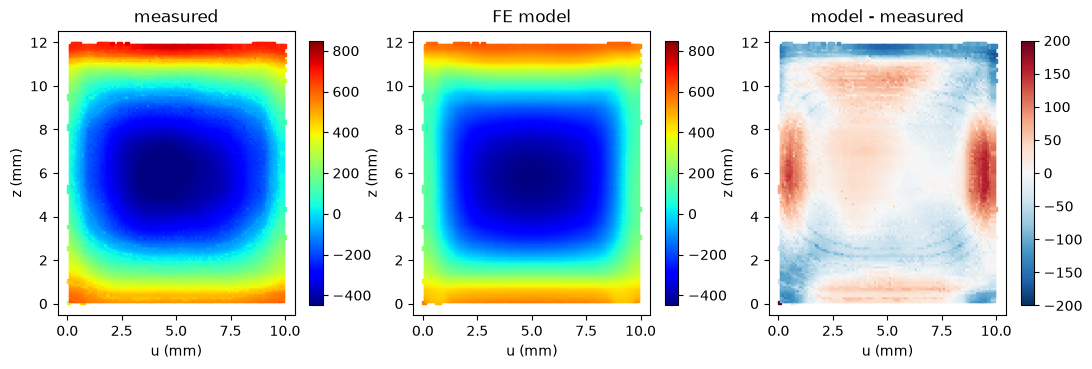

In [6]:
best = cal.report()
fine = Calibration(make(elem=0.5), CSV, EDGE, AZ)
fine.report(dict(zip(NAMES, best["th"])));

## 7. Close MAPDL

In [7]:
mapdl.exit()